# Ejercicio 10. Verificación del par más cercano en una dimensión

Este cuaderno acompaña al informe [`ejercicio-10.md`](ejercicio-10.md).
Ejecuta el mismo código, comprueba la reducción desde distinción de elementos,
vigila la rejilla y contrasta el análisis hacia atrás mediante permutaciones.
También genera `ejercicio-10.png`. Las secciones siguen la numeración del informe.

La cota $\Omega(n\log n)$ corresponde a árboles algebraicos de grado constante.
La rejilla permite $O(n)$ esperado en una RAM con aritmética exacta, parte entera
y hashing de costo esperado constante. Las medidas cuentan operaciones del
algoritmo; no afirman costo constante en bits para enteros y fracciones grandes.
Se usan `int` y `Fraction` para calcular las celdas exactamente.

Para reproducirlo hacen falta Python 3, `matplotlib` e `IPython`.


In [1]:
from collections import Counter
from fractions import Fraction
from itertools import permutations, product
from math import factorial
from random import Random

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import Image, display


## 1. Formulación y modelos

La entrada tiene al menos dos posiciones. Las repeticiones se conservan y la
salida identifica dos posiciones diferentes, incluso si sus valores coinciden.
El oráculo recorre todos los pares y usa aritmética exacta. Su costo cuadrático
pertenece a las pruebas, no a la rejilla.


In [2]:
def brute_force(X):
    if len(X) < 2:
        raise ValueError('se requieren al menos dos posiciones')
    distance, i, j = min((abs(X[i] - X[j]), i, j)
                         for i in range(len(X)) for j in range(i + 1, len(X)))
    return distance, (i, j)


def check_answer(X, answer, expected):
    delta, pair = answer[:2]
    i, j = pair
    assert 0 <= i < len(X) and 0 <= j < len(X) and i != j
    assert delta == abs(X[i] - X[j]) == expected


assert brute_force([4, 4]) == (0, (0, 1))
assert brute_force([-8, 0, 4, 12, 3])[0] == 1


## 2. Reducción y cota algebraica

La transformación desde distinción de elementos es la identidad: se entrega la
misma lista al algoritmo de par más cercano y se pregunta si el mínimo es cero.
Si se devuelve un par de índices, la prueba final es $x_i-x_j=0$, de grado 1.
Un árbol de profundidad $T(n)$ daría uno de profundidad $T(n)+1$ para distinción.
El teorema citado en la conferencia 2 y en el
[artículo de Ben-Or, secciones 5 y 6](https://ic.unicamp.br/~rezende/ensino/mo619/Ben-Or%2CAlgebraicComputationTrees1983.pdf)
da la cota $\Omega(n\log n)$ para grado constante.

La cota se alcanza ordenando y revisando pares consecutivos: cualquier diferencia
entre dos posiciones ordenadas es una suma de huecos no negativos y alguno
de esos huecos no la supera. El código siguiente es idéntico al del informe.


In [3]:
def closest_pair_sorted(X):
    if len(X) < 2:
        raise ValueError("se requieren al menos dos posiciones")
    order = sorted(range(len(X)), key=X.__getitem__)
    pair = (order[0], order[1])
    delta = X[pair[1]] - X[pair[0]]
    for k in range(1, len(order) - 1):
        i, j = order[k], order[k + 1]
        distance = X[j] - X[i]
        if distance < delta:
            delta, pair = distance, (i, j)
    return delta, pair


## 3. Adaptación del algoritmo incremental aleatorio

La celda es $\lfloor x/\delta\rfloor$ y representa $[c\delta,(c+1)\delta)$.
Dos puntos de una misma celda distarían menos que $\delta$. Toda mejora del mínimo
está en la celda del punto nuevo o en una de las dos vecinas. Se consulta la
rejilla con su escala anterior y se reconstruye solo tras una mejora positiva.
Una distancia cero termina inmediatamente, sin dividir por cero.

La función pública baraja los índices; el núcleo también permite verificar
órdenes concretos. Las cuatro estadísticas cuentan consultas, distancias,
escrituras de puntos y reconstrucciones. El código es idéntico al del informe.


In [4]:
from random import Random


def _closest_pair_order(X, order):
    if len(X) < 2:
        raise ValueError("se requieren al menos dos posiciones")
    i, j = order[0], order[1]
    pair = (i, j)
    delta = abs(X[i] - X[j])
    stats = dict(probes=0, distances=1, placements=0, rebuilds=0)
    if delta == 0:
        return delta, pair, stats
    grid = {}
    for index in order[:2]:
        grid[X[index] // delta] = index
        stats["placements"] += 1
    for t in range(2, len(order)):
        index = order[t]
        old_delta = delta
        c = X[index] // old_delta
        for cell in (c - 1, c, c + 1):
            stats["probes"] += 1
            other = grid.get(cell)
            if other is not None:
                distance = abs(X[index] - X[other])
                stats["distances"] += 1
                if distance < delta:
                    delta, pair = distance, (index, other)
                    if delta == 0:
                        return delta, pair, stats
        if delta < old_delta:
            stats["rebuilds"] += 1
            grid = {}
            for s in range(t + 1):
                other = order[s]
                grid[X[other] // delta] = other
                stats["placements"] += 1
        else:
            grid[c] = index
            stats["placements"] += 1
    return delta, pair, stats


def closest_pair_grid(X, seed=0):
    order = list(range(len(X)))
    Random(seed).shuffle(order)
    return _closest_pair_order(X, order)


## 4. Correctitud, costo esperado y cambio de modelo

El invariante conserva la distancia mínima del prefijo, un par que la alcanza
y una tabla con todas sus posiciones en celdas distintas. La versión vigilada
comprueba esas tres propiedades contra el oráculo, además de la cobertura de
todas las posiciones que podrían mejorar el mínimo. Las posiciones pendientes
disminuyen en cada inserción; cada paso consulta tres celdas y reconstruye a
lo sumo una vez. La corrección vale para cualquier orden.

Para el costo, fijado el conjunto de las primeras $k$ posiciones, se elige un
par mínimo canónico. Solo si el último elemento es uno de sus dos extremos
puede bajar el mínimo. Por tanto, $\Pr(R_k=1)\le2/k$, incluso con empates.
La reconstrucción cuesta $O(k)$ y la suma de esos costos esperados es $O(n)$.
Las operaciones de parte entera y hash son las que cambian el modelo de la cota.


In [5]:
def watched_order(X, order):
    i, j = order[0], order[1]
    pair = (i, j)
    delta = abs(X[i] - X[j])
    stats = dict(probes=0, distances=1, placements=0, rebuilds=0)
    trace = []
    if delta == 0:
        trace.append(dict(k=2, index=None, old=None, delta=delta,
                          action='terminar en cero', writes=0))
        return (delta, pair, stats), trace
    grid = {}

    def place(index):
        cell = X[index] // delta
        assert cell not in grid
        grid[cell] = index
        stats['placements'] += 1

    def invariant(k):
        prefix = order[:k]
        expected = brute_force([X[index] for index in prefix])[0]
        assert delta == expected > 0
        assert pair[0] in prefix and pair[1] in prefix and pair[0] != pair[1]
        assert abs(X[pair[0]] - X[pair[1]]) == delta
        assert len(grid) == k and set(grid.values()) == set(prefix)
        assert all(X[index] // delta == cell for cell, index in grid.items())

    for index in order[:2]:
        place(index)
    trace.append(dict(k=2, index=None, old=None, delta=delta,
                      action='inicializar', writes=2))
    invariant(2)
    for t in range(2, len(order)):
        index = order[t]
        old_delta = delta
        c = X[index] // old_delta
        queried = (c - 1, c, c + 1)
        improving = {j for j in order[:t] if abs(X[index] - X[j]) < old_delta}
        accessible = {grid[cell] for cell in queried if cell in grid}
        assert improving <= accessible
        before_writes = stats['placements']
        for cell in queried:
            stats['probes'] += 1
            other = grid.get(cell)
            if other is not None:
                assert other in order[:t] and other != index
                distance = abs(X[index] - X[other])
                stats['distances'] += 1
                if distance < delta:
                    delta, pair = distance, (index, other)
                    if delta == 0:
                        assert brute_force([X[j] for j in order[:t+1]])[0] == 0
                        trace.append(dict(k=t+1, index=index, old=old_delta, delta=delta,
                                          action='terminar en cero', writes=0))
                        return (delta, pair, stats), trace
        if delta < old_delta:
            stats['rebuilds'] += 1
            grid = {}
            for other in order[:t+1]:
                place(other)
            action = 'reconstruir'
        else:
            place(index)
            action = 'insertar'
        invariant(t + 1)
        assert len(X) - (t + 1) == len(X) - t - 1 >= 0
        trace.append(dict(k=t+1, index=index, old=old_delta, delta=delta,
                          action=action, writes=stats['placements'] - before_writes))
    return (delta, pair, stats), trace


def verify_order(X, order):
    assert sorted(order) == list(range(len(X)))
    snapshot = tuple(X)
    expected = brute_force(X)[0]
    actual = _closest_pair_order(X, order)
    watched, trace = watched_order(X, order)
    assert actual == watched
    check_answer(X, actual, expected)
    check_answer(X, closest_pair_sorted(X), expected)
    n = len(X)
    stats = actual[2]
    assert stats['probes'] <= 3 * (n - 2)
    assert stats['distances'] <= 1 + 3 * (n - 2)
    assert stats['rebuilds'] <= n - 2
    predicted = n + sum((r['k'] - 1) for r in trace if r['action'] == 'reconstruir')
    assert stats['placements'] <= predicted
    if expected > 0:
        assert stats['placements'] == predicted
    assert tuple(X) == snapshot
    return actual, trace


example = [-8, 0, 4, 12, 3]
example_answer, example_trace = verify_order(example, list(range(5)))
assert example_answer == (1, (4, 2), dict(probes=9, distances=5, placements=11, rebuilds=2))
assert [(r['k'], r['old'], r['delta'], r['action'], r['writes']) for r in example_trace] == [
    (2, None, 8, 'inicializar', 2), (3, 8, 4, 'reconstruir', 3),
    (4, 4, 4, 'insertar', 1), (5, 4, 1, 'reconstruir', 5),
]
print('Tabla 1. Traza de [-8,0,4,12,3] en ese orden')
print('paso  valor  delta anterior  delta nueva  acción        escrituras')
for r in example_trace:
    value = '-8,0' if r['k'] == 2 else str(example[r['index']])
    print(f'{r["k"]:4} {value:>6} {str(r["old"]):>15} {str(r["delta"]):>12} '
          f'{r["action"]:13} {r["writes"]:10}')
print('Distancia y posiciones:', example_answer[:2])
print('Estadísticas:', example_answer[2])


Tabla 1. Traza de [-8,0,4,12,3] en ese orden
paso  valor  delta anterior  delta nueva  acción        escrituras
   2   -8,0            None            8 inicializar            2
   3      4               8            4 reconstruir            3
   4     12               4            4 insertar               1
   5      3               4            1 reconstruir            5
Distancia y posiciones: (1, (4, 2))
Estadísticas: {'probes': 9, 'distances': 5, 'placements': 11, 'rebuilds': 2}


### Análisis hacia atrás y un orden cuadrático

Sea $W$ el número de escrituras de puntos en tablas. Sin salida anticipada,
$W=n+\sum_{k=3}^n(k-1)R_k$. La cota $\Pr(R_k=1)\le2/k$ implica
$\mathbb E[W]\le3n-4$ y $\mathbb E[\sum R_k]\le2H_n-3$.
La cota es sobre la esperanza, no sobre cada ejecución.

El orden $0,1,1/2,1/4,\ldots,2^{-(n-2)}$ reconstruye en cada inserción.
Se comprueban exactamente $n-2$ reconstrucciones y $n(n+1)/2-1$ escrituras,
usando `Fraction` para no introducir redondeos ni subdesbordamientos.


In [6]:
def halves_family(n):
    return [Fraction(0), Fraction(1)] + [Fraction(1, 2**k) for k in range(1, n - 1)]


quadratic_records = []
for n in range(2, 65):
    X = halves_family(n)
    result, trace = verify_order(X, list(range(n)))
    assert result[0] == Fraction(1, 2**(n - 2))
    assert result[2]['rebuilds'] == n - 2
    writes = result[2]['placements']
    assert writes == n * (n + 1) // 2 - 1
    quadratic_records.append((n, writes))
print('ok: 63 órdenes cuadráticos, para cada largo de 2 a 64')
print(' n   reconstrucciones   escrituras sin barajar')
for n in [2, 4, 8, 16, 32, 64]:
    print(f'{n:2} {n-2:18} {n*(n+1)//2-1:24}')


ok: 63 órdenes cuadráticos, para cada largo de 2 a 64
 n   reconstrucciones   escrituras sin barajar
 2                  0                        2
 4                  2                        9
 8                  6                       35
16                 14                      135
32                 30                      527
64                 62                     2079


## 5. Verificación numérica

Se enumeran todos los arreglos de largos 2 a 7 sobre $\{-1,0,1\}$, y para
cada uno se prueban tres permutaciones con semillas fijas. Se verifica
la equivalencia entre distancia cero y repetidos, el resultado contra fuerza
bruta, los índices devueltos y el invariante del prefijo y la rejilla.

Después se comprueban casos racionales, negativos y valores en bordes de celda,
también en todas sus permutaciones. La función pública que baraja se contrasta
con el núcleo usando el mismo orden y semilla.


In [7]:
exhaustive_arrays = 0
exhaustive_runs = 0
for n in range(2, 8):
    for X in product([-1, 0, 1], repeat=n):
        expected = brute_force(X)[0]
        assert (expected == 0) == (len(set(X)) < n)
        for seed in [0, 1, 2026]:
            order = list(range(n))
            Random(seed).shuffle(order)
            result, trace = verify_order(X, order)
            assert closest_pair_grid(X, seed=seed) == result
            exhaustive_runs += 1
        exhaustive_arrays += 1
assert exhaustive_arrays == 3276 and exhaustive_runs == 9828
print(f'ok: {exhaustive_arrays} arreglos exhaustivos, {exhaustive_runs} ejecuciones')

rational_cases = [
    [Fraction(-3, 2), Fraction(-1, 2), Fraction(1, 2), Fraction(3, 2)],
    [Fraction(-1, 3), Fraction(0), Fraction(1, 6), Fraction(1, 3)],
    [Fraction(2, 7), Fraction(-2, 7), Fraction(2, 7)],
    [-12, -8, -4, 0, 4],
    [10**40, 10**40 + 1, -10**40, 0],
]
rational_runs = 0
for X in rational_cases:
    for order in permutations(range(len(X))):
        verify_order(X, order)
        rational_runs += 1
print(f'ok: {rational_runs} permutaciones adicionales con racionales, bordes y magnitudes grandes')

invalid_cases = [[], [0]]
for X in invalid_cases:
    for algorithm in [closest_pair_sorted, closest_pair_grid]:
        try:
            algorithm(X)
        except ValueError:
            pass
        else:
            raise AssertionError('debió rechazarse un largo menor que dos')
print('ok: ambas funciones rechazan largos 0 y 1')


ok: 3276 arreglos exhaustivos, 9828 ejecuciones
ok: 198 permutaciones adicionales con racionales, bordes y magnitudes grandes
ok: ambas funciones rechazan largos 0 y 1


### Todas las permutaciones y la frecuencia exacta de reconstrucción

Se toma $X=[1,2,4,\ldots,2^{n-1}]$, para $2\le n\le7$.
Las diferencias positivas entre potencias de dos son distintas: en
$2^b-2^a=2^a(2^{b-a}-1)$, el factor impar determina el segundo exponente
una vez fijado el primero. Así, cada subconjunto tiene un único par mínimo.
En esta familia, insertar un extremo de ese par es también suficiente para
bajar el mínimo, y la frecuencia de reconstrucción es exactamente $2/k$.

Se enumeran todas las permutaciones y se usan fracciones para comprobar sin
redondeo la frecuencia por paso, la media de reconstrucciones $2H_n-3$ y la
media de escrituras $3n-1-2H_n$. En otras entradas esas expresiones dan cotas
superiores, no necesariamente igualdades.


In [8]:
permutation_runs = 0
permutation_records = []
for n in range(2, 8):
    X = [2**k for k in range(n)]
    event_counts = Counter()
    total_rebuilds = 0
    total_writes = 0
    for order in permutations(range(n)):
        result, trace = verify_order(X, order)
        for r in trace:
            if r['action'] == 'reconstruir':
                event_counts[r['k']] += 1
        total_rebuilds += result[2]['rebuilds']
        total_writes += result[2]['placements']
        permutation_runs += 1
    number = factorial(n)
    harmonic = sum((Fraction(1, k) for k in range(1, n + 1)), Fraction(0))
    for k in range(3, n + 1):
        assert Fraction(event_counts[k], number) == Fraction(2, k)
    mean_rebuilds = Fraction(total_rebuilds, number)
    mean_writes = Fraction(total_writes, number)
    assert mean_rebuilds == 2 * harmonic - 3
    assert mean_writes == 3 * n - 1 - 2 * harmonic
    assert mean_writes <= 3 * n - 4
    permutation_records.append((n, number, mean_rebuilds, mean_writes))
assert permutation_runs == 5912
print(' n  permutaciones  reconstrucciones medias exactas  escrituras medias exactas')
for n, number, mean_rebuilds, mean_writes in permutation_records:
    print(f'{n:2} {number:14} {str(mean_rebuilds):32} {str(mean_writes):25}')
print(f'ok: {permutation_runs} permutaciones; frecuencia por paso exactamente 2/k')


 n  permutaciones  reconstrucciones medias exactas  escrituras medias exactas
 2              2 0                                2                        
 3              6 2/3                              13/3                     
 4             24 7/6                              41/6                     
 5            120 47/30                            283/30                   
 6            720 19/10                            121/10                   
 7           5040 153/70                           1037/70                  
ok: 5912 permutaciones; frecuencia por paso exactamente 2/k


### Tabla 2. Medición con tamaños mayores

Para cada largo se fijan enteros distintos elegidos con semilla $10000+n$.
Solo varía el orden, con las semillas 0 a 63. El código público se ejecuta en
cada caso y la referencia ordenada comprueba el resultado. Se cuentan escrituras
de puntos y reconstrucciones; las medias son mediciones y no valores exactos
de la esperanza. La columna $3n-4$ es una cota de la esperanza de escrituras.


In [9]:
measurement_records = []
measurement_runs = 0
for n in [16, 32, 64, 128, 256, 512, 1024]:
    X = Random(10000 + n).sample(range(-10**9, 10**9), n)
    expected = closest_pair_sorted(X)[0]
    writes = []
    rebuilds = []
    for seed in range(64):
        result = closest_pair_grid(X, seed=seed)
        check_answer(X, result, expected)
        assert result[2]['probes'] == 3 * (n - 2)
        assert result[2]['distances'] <= 1 + 3 * (n - 2)
        writes.append(result[2]['placements'])
        rebuilds.append(result[2]['rebuilds'])
        measurement_runs += 1
    measurement_records.append(dict(n=n, runs=64, writes=sum(writes)/64,
                                     rebuilds=sum(rebuilds)/64, upper=3*n-4))
assert measurement_runs == 448
print('Tabla 2. Medias sobre 64 órdenes por entrada fija')
print('   n  escrituras medias  reconstrucciones medias  cota E[escrituras]')
for r in measurement_records:
    print(f'{r["n"]:4} {r["writes"]:18.2f} {r["rebuilds"]:24.2f} {r["upper"]:19}')
print(f'ok: {measurement_runs} ejecuciones de tamaños mayores con resultado verificado')


Tabla 2. Medias sobre 64 órdenes por entrada fija
   n  escrituras medias  reconstrucciones medias  cota E[escrituras]
  16              42.14                     4.06                  44
  32              87.75                     5.25                  92
  64             176.23                     6.08                 188
 128             374.42                     7.89                 380
 256             801.50                     9.33                 764
 512            1543.30                    10.55                1532
1024            2911.61                    11.83                3068
ok: 448 ejecuciones de tamaños mayores con resultado verificado


La media muestral no tiene por qué quedar por debajo de una cota de la esperanza. Para $n=256$, las 64 ejecuciones dan una media de 801.50 escrituras, mayor que 764. Una muestra finita puede superar la esperanza verdadera; la desigualdad $\mathbb E[W]\le3n-4$ no es una cota por ejecución ni por muestra.

## Figura 1

A la izquierda se representa el último paso de la Tabla 1, antes de reconstruir.
El punto nuevo, 3, consulta su intervalo $[0,4)$ y sus dos vecinos. Allí
encuentra 0 y 4, y el mínimo baja de 4 a 1. A la derecha se muestran escrituras
de puntos: las medias medidas en órdenes aleatorios, la cota lineal de su
esperanza y la familia cuadrática en un orden desfavorable. Se usan ejes
logarítmicos para distinguir los crecimientos sin medir segundos.


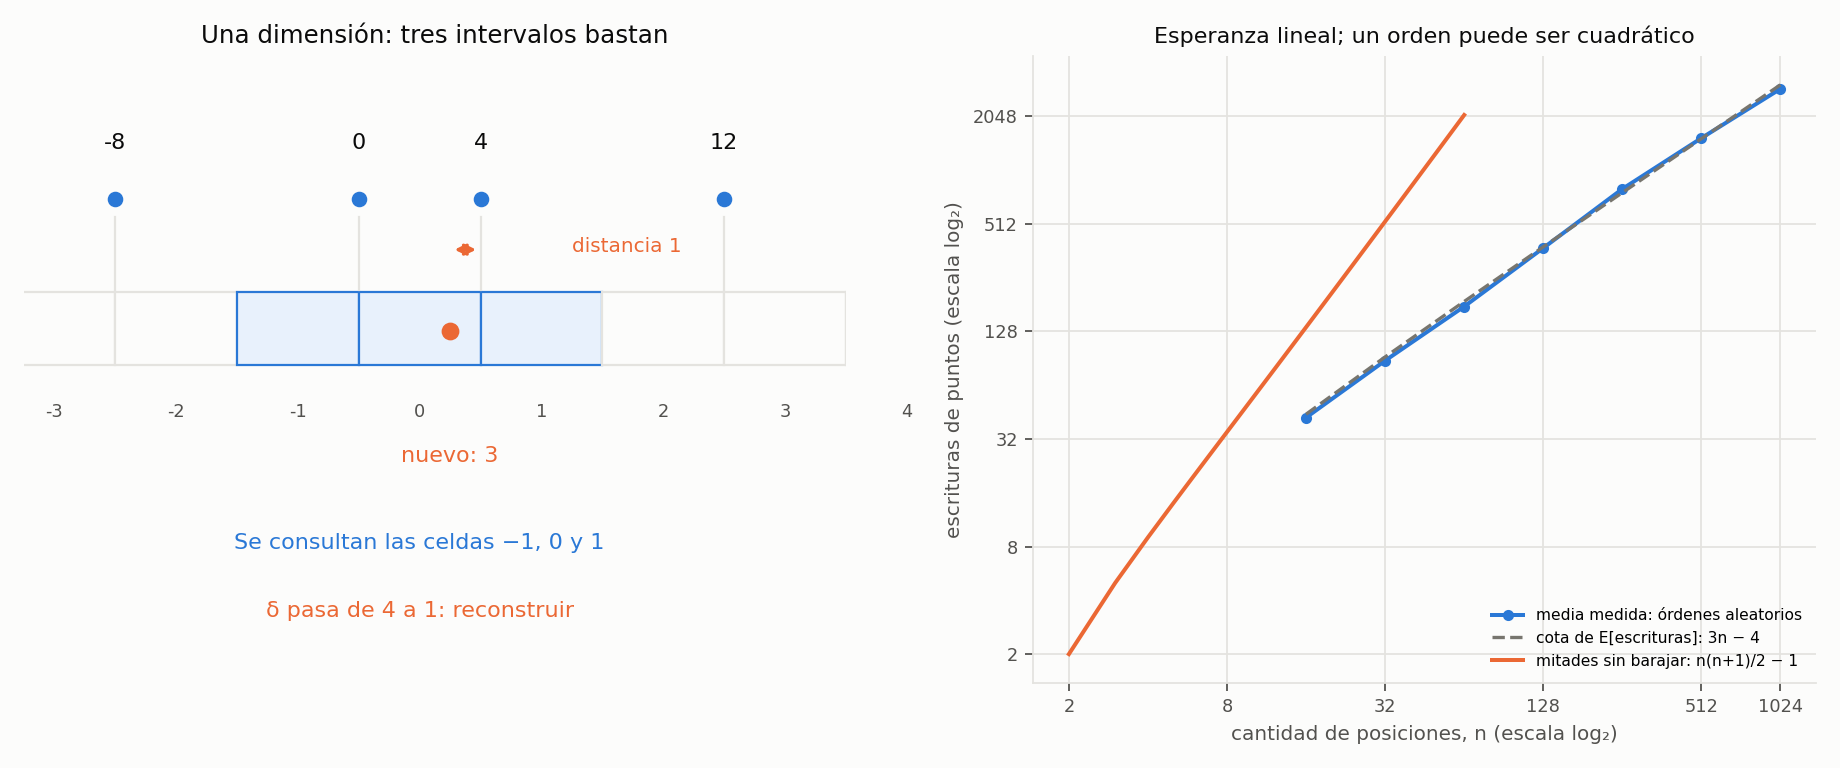

In [10]:
blue, orange = '#2a78d6', '#eb6834'
ink, secondary = '#0b0b0b', '#52514e'
grid_color, background = '#e4e3df', '#fcfcfb'
fig, (ax_grid, ax_cost) = plt.subplots(1, 2, figsize=(11.5, 4.8), dpi=160,
                                         gridspec_kw={'width_ratios': [1.05, 1]})
fig.patch.set_facecolor(background)

for c in range(-3, 5):
    queried = c in [-1, 0, 1]
    ax_grid.add_patch(Rectangle((4*c, -.27), 4, .54,
                                facecolor='#e8f1fc' if queried else background,
                                edgecolor=blue if queried else grid_color, lw=1))
    ax_grid.text(4*c+2, -.65, str(c), ha='center', color=secondary, fontsize=8)
for value in [-8, 0, 4, 12]:
    ax_grid.plot(value, .95, 'o', color=blue, ms=6)
    ax_grid.plot([value, value], [.82, .28], color=grid_color, lw=1)
    ax_grid.text(value, 1.32, str(value), ha='center', color=ink, fontsize=10)
ax_grid.plot(3, -.02, 'o', color=orange, ms=7)
ax_grid.text(3, -.98, 'nuevo: 3', ha='center', color=orange, fontsize=10)
ax_grid.annotate('', xy=(4, .58), xytext=(3, .58),
                 arrowprops=dict(arrowstyle='<->', color=orange, lw=1.5))
ax_grid.text(7, .6, 'distancia 1', color=orange, fontsize=9, va='center')
ax_grid.text(2, -1.62, 'Se consultan las celdas −1, 0 y 1',
              ha='center', color=blue, fontsize=10)
ax_grid.text(2, -2.12, 'δ pasa de 4 a 1: reconstruir',
              ha='center', color=orange, fontsize=10)
ax_grid.set_title('Una dimensión: tres intervalos bastan', color=ink, fontsize=11)
ax_grid.set_xlim(-11, 16)
ax_grid.set_ylim(-2.6, 2)
ax_grid.axis('off')

ns = [r['n'] for r in measurement_records]
means = [r['writes'] for r in measurement_records]
uppers = [r['upper'] for r in measurement_records]
ax_cost.plot(ns, means, '-o', color=blue, lw=1.8, ms=4,
             label='media medida: órdenes aleatorios')
ax_cost.plot(ns, uppers, '--', color='#77756e', lw=1.5,
             label='cota de E[escrituras]: 3n − 4')
worst_ns = [n for n, writes in quadratic_records]
worst_writes = [writes for n, writes in quadratic_records]
ax_cost.plot(worst_ns, worst_writes, color=orange, lw=1.8,
             label='mitades sin barajar: n(n+1)/2 − 1')
ax_cost.set_xscale('log', base=2)
ax_cost.set_yscale('log', base=2)
ax_cost.set_xticks([2, 8, 32, 128, 512, 1024], labels=['2','8','32','128','512','1024'])
ax_cost.set_yticks([2, 8, 32, 128, 512, 2048], labels=['2','8','32','128','512','2048'])
ax_cost.set_xlabel('cantidad de posiciones, n (escala log₂)', color=secondary, fontsize=9)
ax_cost.set_ylabel('escrituras de puntos (escala log₂)', color=secondary, fontsize=9)
ax_cost.set_title('Esperanza lineal; un orden puede ser cuadrático', color=ink, fontsize=10)
ax_cost.set_facecolor(background)
ax_cost.grid(color=grid_color, lw=.8)
for side in ['top', 'right']:
    ax_cost.spines[side].set_visible(False)
for side in ['left', 'bottom']:
    ax_cost.spines[side].set_color(grid_color)
ax_cost.tick_params(colors=secondary, labelsize=8)
ax_cost.legend(frameon=False, fontsize=7, loc='lower right')
fig.tight_layout(w_pad=2)
fig.savefig('ejercicio-10.png', facecolor=background)
plt.close(fig)
display(Image(filename='ejercicio-10.png'))


## 6. Conclusiones

La misma lista sirve como instancia de par más cercano: la distancia es cero
exactamente cuando hay repetidos. Esto transfiere la cota algebraica
$\Omega(n\log n)$, que alcanza ordenar y revisar vecinos.

La rejilla unidimensional mantiene intervalos de largo igual al mínimo actual
y consulta tres celdas. Su corrección vale para cualquier orden. La permutación
uniforme da probabilidad de reconstrucción a lo sumo $2/k$, de donde sale
el costo esperado lineal. El modelo agrega parte entera y hashing; por eso
la cota algebraica no se aplica. Las pruebas verifican las familias enumeradas;
las demostraciones establecen los resultados generales en esos modelos.


In [11]:
print('Todas las comprobaciones finalizaron correctamente.')
print(f'Arreglos exhaustivos: {exhaustive_arrays}; ejecuciones: {exhaustive_runs}')
print(f'Permutaciones racionales y de bordes: {rational_runs}')
print(f'Permutaciones de potencias de dos: {permutation_runs}')
print('Familia cuadrática: largos 2 a 64')
print(f'Ejecuciones de tamaños mayores: {measurement_runs}')
print('Figura guardada en ejercicio-10.png')


Todas las comprobaciones finalizaron correctamente.
Arreglos exhaustivos: 3276; ejecuciones: 9828
Permutaciones racionales y de bordes: 198
Permutaciones de potencias de dos: 5912
Familia cuadrática: largos 2 a 64
Ejecuciones de tamaños mayores: 448
Figura guardada en ejercicio-10.png
